In [7]:
import pandas as pd
import numpy as np
import pickle

In [8]:
df = pd.read_csv("../data/Algerian_forest_fires_Cleaned_dataset.csv")

df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0,0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,0,0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,0,0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,0,0
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,0,0


In [9]:
model = pickle.load(open("../models/linear_regression.pkl", "rb"))
scaler = pickle.load(open("../models/scaler.pkl", "rb"))

print("Model and scaler loaded successfully!")

Model and scaler loaded successfully!


In [10]:
from sklearn.model_selection import train_test_split

# Prepare features and target
df.drop(["day", "month", "year"], axis=1, inplace=True)

X = df.drop(["FWI", "DC", "BUI", "Classes"], axis=1)
y = df["FWI"]

# Recreate the same train-test split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,random_state=42)

print("Features:", X.columns.tolist())
print("Test shape:", X_test.shape)

Features: ['Temperature', 'RH', 'Ws', 'Rain', 'FFMC', 'DMC', 'ISI', 'Region']
Test shape: (61, 8)


In [11]:
X_test_scaled = scaler.transform(X_test)

print("Test data scaled successfully!")

Test data scaled successfully!


In [12]:
y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")
print(y_pred[:10])

Predictions generated successfully!
[ 8.06948252  7.57969477 -0.26984676  4.6795948   6.47398459  1.61726263
  1.76367696  7.3662821   2.08357538  3.52956271]


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 0.5806361642310044
MSE : 0.7510067624494436
RMSE: 0.8666064634246872
R2  : 0.9830321384727897


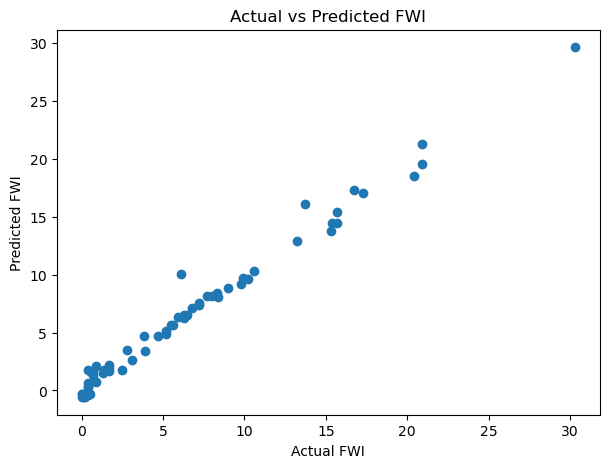

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual FWI")
plt.ylabel("Predicted FWI")
plt.title("Actual vs Predicted FWI")
plt.show()

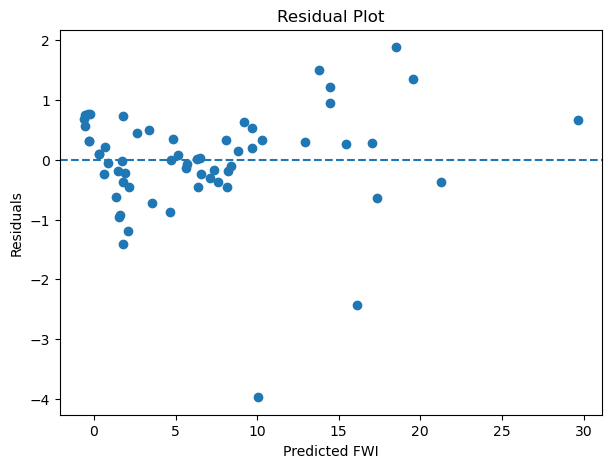

In [15]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted FWI")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

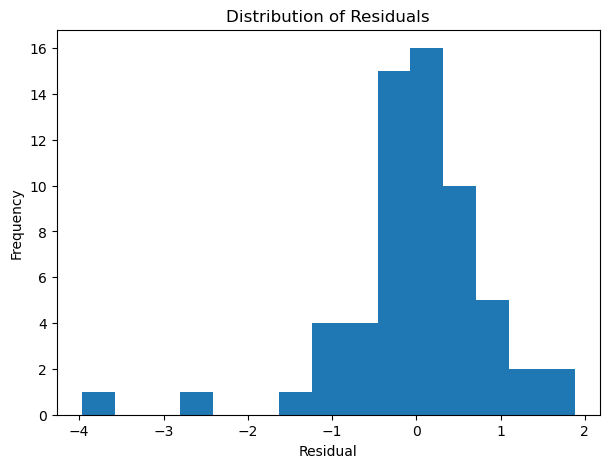

In [16]:
plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=15)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()